# Nifty 50 Clustering: Grouping Companies by Market Behavior, Not Just Sector Labels

Index providers assign every Nifty 50 company to one GICS-style industry
label, but two companies in the same labeled industry can behave very
differently in the market (one defensive and low-volatility, another
high-growth and volatile), while two companies from different industries
can move almost identically. This notebook groups the 50 constituents by
their actual 3-year market behavior, annualized return, volatility, beta
to the index, liquidity, drawdown risk, and risk-adjusted return, combined
with their stated industry, using three unsupervised clustering algorithms:
Agglomerative Hierarchical Clustering, KMeans, and KMeans++. The groups
that fall out are a more honest basis for portfolio diversification and
sector-neutral strategy design than the static industry label alone.

The source list (`Nifty 50 List.csv`) has no numeric columns at all, only
company identifiers and an industry label, so the numeric features this
analysis clusters on are derived from real historical price data fetched
live from Yahoo Finance, not invented. This is deliberately unsupervised:
there is no target column and no train/test split, every company receives
a cluster assignment from the complete dataset.

# 1 · Imports & Configuration

Core stack: **pandas**/**NumPy** for tabular work, **matplotlib**/
**seaborn** for visualization, **yfinance** for the real market-data fetch,
**scipy** for the hierarchical linkage/dendrogram and pairwise distances
(Dunn index), **scikit-learn** for scaling, encoding, the three clustering
algorithms, silhouette scoring, and PCA. Warnings are silenced globally so
benign library chatter doesn't clutter the output.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

import logging
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

/Users/vigneshramesh/Documents/Scaler python/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


# 2 · Secure AI Setup (Gemini via Google AI Studio)

Gemini is called once per major analytical stage to turn computed
numbers into a decision-ready narrative. The API key loads from a local
`.env` file (never hardcoded), a fallback chain of models is tried in order
on any exception with one retry per model, and the SDK's internal
`google_genai.types` logger is raised to `ERROR` immediately so an internal
"thought signature" notice never appears as a spurious warning box.

In [2]:
from dotenv import load_dotenv
from google import genai
from google.genai import types

load_dotenv(Path.cwd() / ".env")
logging.getLogger("google_genai.types").setLevel(logging.ERROR)

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
GEMINI_MODEL_CHAIN = [
    model.strip()
    for model in os.getenv(
        "GEMINI_MODEL", "gemini-3.6-flash,gemini-3.5-flash-lite,gemini-flash-lite-latest"
    ).split(",")
]
_client = (
    genai.Client(api_key=GOOGLE_API_KEY, http_options=types.HttpOptions(timeout=45_000))
    if GOOGLE_API_KEY else None
)

def generate_insight(analysis_topic, data_summary):
    fallback = (
        "**AI narrative unavailable**: set `GOOGLE_API_KEY` in `.env` to enable Gemini-generated "
        "insights. Review the computed metrics and chart above directly.\n\n"
        f"Computed summary:\n\n{data_summary}"
    )
    if _client is None:
        return fallback
    prompt = (
        "You are a senior quantitative portfolio analyst presenting cluster-analysis findings "
        "to an asset management team.\n"
        f"Analysis topic: {analysis_topic}\n\n"
        f"Computed data summary:\n{data_summary}\n\n"
        "Write a concise, decision-ready insight (3-5 sentences) followed by 2-4 bullet-point "
        "recommendations, in markdown. Reference the specific numbers given. Go at least one "
        "level deeper than the raw pattern: suggest a plausible root cause, not just the "
        "surface observation. Where a recommendation implies action, suggest a plausible owner "
        "(e.g. the portfolio construction team, risk management) or timeframe only where it "
        "genuinely fits, not forced into every bullet. Wherever the data supports it, quantify "
        "the expected impact of a recommendation (a rough magnitude or percentage), grounded "
        "only in the numbers given, never invented. Do not restate the raw numbers as a table; "
        "weave them into the narrative. Use clear, well-punctuated sentences (commas, periods, "
        "colons, semicolons, and parentheses only). Do not use em dashes anywhere in the response."
    )
    last_error = None
    for model_name in GEMINI_MODEL_CHAIN:
        for attempt in range(2):
            try:
                response = _client.models.generate_content(model=model_name, contents=prompt)
                return response.text
            except Exception as exc:
                last_error = exc
                if attempt == 0:
                    time.sleep(2)
    return fallback + f"\n\n_(Gemini call failed on all models in the fallback chain: {last_error})_"


# 3 · Data Dictionary

**Source list** (`Nifty 50 List.csv`, 50 rows): `Company Name`,
`Industry` (13 distinct values, used as the categorical clustering
feature), `Symbol` (NSE ticker, used to fetch market data), `Series`
(constant `EQ`, no information, dropped), `ISIN Code` (unique identifier,
dropped).

**Derived numeric features** (fetched from 3 years of daily price/volume
history per symbol, not present in the source list):

| Feature | Definition |
|---|---|
| `Annual_Return` | mean daily return × 252 |
| `Annual_Volatility` | standard deviation of daily return × √252 |
| `Beta` | covariance(stock return, Nifty index return) / variance(index return) |
| `Avg_Daily_Volume` | mean daily traded volume (log-transformed before scaling, see Section 7) |
| `Max_Drawdown` | minimum of (cumulative return ÷ running-max cumulative return − 1) |
| `Sharpe_Ratio` | `Annual_Return / Annual_Volatility` (risk-free rate treated as 0) |

# 4 · Loading the Source List

The source list loads as-is, nothing touched yet. There is no
train/test split anywhere in this notebook: clustering is unsupervised, and
every one of the 50 companies gets a cluster assignment from the complete
dataset, there is no held-out evaluation set the way a supervised case
study would have.

In [3]:
DATA_DIR = Path("../Datasets/Practice/Agglomorative_HeirarchialCLustering/Nifty_50")
listing = pd.read_csv(DATA_DIR / "Nifty 50 List.csv")
listing.columns = [c.strip() for c in listing.columns]

print("Shape:", listing.shape)
print("Duplicate symbols:", listing["Symbol"].duplicated().sum())
listing.head()

Shape: (50, 5)
Duplicate symbols: 0


,Company Name,Industry,Symbol,Series,ISIN Code
0,Adani Ports and Special Economic Zone Ltd.,SERVICES,ADANIPORTS,EQ,INE742F01042
1,Asian Paints Ltd.,CONSUMER GOODS,ASIANPAINT,EQ,INE021A01026
2,Axis Bank Ltd.,FINANCIAL SERVICES,AXISBANK,EQ,INE238A01034
3,Bajaj Auto Ltd.,AUTOMOBILE,BAJAJ-AUTO,EQ,INE917I01010
4,Bajaj Finance Ltd.,FINANCIAL SERVICES,BAJFINANCE,EQ,INE296A01024


# 5 · Data Acquisition: Deriving Numeric Features via Yahoo Finance

The source list has no numeric columns, so there is nothing to
cluster on as-is. Three years of daily price/volume history is fetched per
NSE symbol (ticker `SYMBOL.NS`) via `yfinance`, plus the Nifty index
(`^NSEI`) as the beta reference, and the six features in the data
dictionary are derived from each company's daily return series. The fetch
result is cached to `nifty50_features_raw.csv`; later runs load the cache
directly instead of re-hitting the API, while a missing/deleted cache
triggers a full re-fetch, keeping the pipeline reproducible from scratch.

In [4]:
FEATURE_CACHE = DATA_DIR / "nifty50_features_raw.csv"
PERIOD = "3y"
INDEX_TICKER = "^NSEI"

def fetch_nifty_features(listing_df):
    index_hist = yf.download(INDEX_TICKER, period=PERIOD, progress=False, auto_adjust=True)
    if isinstance(index_hist.columns, pd.MultiIndex):
        index_hist.columns = index_hist.columns.get_level_values(0)
    index_returns = index_hist["Close"].dropna().pct_change().dropna()

    records = []
    for _, row in listing_df.iterrows():
        symbol = f'{row["Symbol"].strip()}.NS'
        try:
            hist = yf.download(symbol, period=PERIOD, progress=False, auto_adjust=True)
            if isinstance(hist.columns, pd.MultiIndex):
                hist.columns = hist.columns.get_level_values(0)
            close = hist["Close"].dropna()
            if close.shape[0] < 30:
                records.append({"Symbol": row["Symbol"]})
                continue
            volume = hist["Volume"].dropna()
            returns = close.pct_change().dropna()
            aligned = pd.concat([returns, index_returns], axis=1, join="inner")
            aligned.columns = ["stock", "index"]
            beta = aligned["stock"].cov(aligned["index"]) / aligned["index"].var()
            cum = (1 + returns).cumprod()
            drawdown = (cum - cum.cummax()) / cum.cummax()
            ann_return = returns.mean() * 252
            ann_vol = returns.std() * np.sqrt(252)
            records.append({
                "Symbol": row["Symbol"],
                "Annual_Return": ann_return,
                "Annual_Volatility": ann_vol,
                "Beta": beta,
                "Avg_Daily_Volume": volume.mean(),
                "Max_Drawdown": drawdown.min(),
                "Sharpe_Ratio": ann_return / ann_vol if ann_vol else np.nan,
            })
        except Exception:
            records.append({"Symbol": row["Symbol"]})
        time.sleep(0.1)
    return listing_df.merge(pd.DataFrame(records), on="Symbol", how="left")

if FEATURE_CACHE.exists():
    df_raw = pd.read_csv(FEATURE_CACHE)
else:
    df_raw = fetch_nifty_features(listing)
    df_raw.to_csv(FEATURE_CACHE, index=False)

print("Shape:", df_raw.shape)
missing_companies = df_raw.loc[df_raw["Annual_Return"].isna(), ["Company Name", "Symbol"]]
print("\nCompanies with a failed/incomplete fetch:")
print(missing_companies.to_string(index=False))
df_raw.head()

Shape: (50, 13)

Companies with a failed/incomplete fetch:
                                Company Name     Symbol
Housing Development Finance Corporation Ltd.       HDFC
                            Tata Motors Ltd. TATAMOTORS


,Company Name,Industry,Symbol,Series,ISIN Code,YF_Symbol,n_rows,Annual_Return,Annual_Volatility,Beta,Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio
0,Adani Ports and Special Economic Zone Ltd.,SERVICES,ADANIPORTS,EQ,INE742F01042,ADANIPORTS.NS,742,0.360288,0.343782,1.569218,3.497456e+06,-0.337767,1.048015
1,Asian Paints Ltd.,CONSUMER GOODS,ASIANPAINT,EQ,INE021A01026,ASIANPAINT.NS,742,-0.028363,0.216859,0.759032,1.204637e+06,-0.368727,-0.130789
2,Axis Bank Ltd.,FINANCIAL SERVICES,AXISBANK,EQ,INE238A01034,AXISBANK.NS,742,0.159128,0.240987,1.134260,8.036348e+06,-0.280270,0.660319
3,Bajaj Auto Ltd.,AUTOMOBILE,BAJAJ-AUTO,EQ,INE917I01010,BAJAJ-AUTO.NS,742,0.268700,0.257564,0.861837,4.238658e+05,-0.423135,1.043234
4,Bajaj Finance Ltd.,FINANCIAL SERVICES,BAJFINANCE,EQ,INE296A01024,BAJFINANCE.NS,742,0.202525,0.281339,1.253002,1.016906e+07,-0.267422,0.719861


In [5]:
acquisition_summary = (
    f"{df_raw.shape[0]} companies total. {missing_companies.shape[0]} companies have no usable "
    f"price history: {', '.join(missing_companies['Symbol'].tolist())}. HDFC merged into HDFC "
    f"Bank in 2023 and no longer trades as a standalone ticker; TATAMOTORS currently returns "
    f"'quote not found' on Yahoo Finance, consistent with Tata Motors' 2024 corporate "
    f"restructuring. Both will be numerically imputed in the cleaning phase rather than dropped, "
    f"since dropping would remove them from the clustering deliverable entirely."
)
display(Markdown(generate_insight("Data acquisition: fetch coverage and failure causes", acquisition_summary)))

Out of 50 total companies evaluated for cluster analysis, 2 constituents (HDFC and TATAMOTORS) currently lack usable price histories due to acquisition failures. A root cause evaluation indicates that these gaps stem from upstream vendor symbol unmapping following structural corporate events: HDFC merged into HDFC Bank in 2023 and no longer trades as a standalone ticker, while TATAMOTORS returned quote not found on Yahoo Finance following its 2024 corporate restructuring. Relying on static public vendor identifiers creates systemic vulnerabilities whenever corporate reorganizations invalidate historical tickers. Consequently, we will numerically impute price histories for both assets during the data cleaning phase rather than dropping them, preserving complete asset representation in the final deliverable.

* **Data Engineering (Cleaning Sprint):** Execute numerical imputation for HDFC and TATAMOTORS to retain 100% universe representation (50 of 50 assets), preventing a 4% (2 of 50 assets) scope reduction in the final clustering output.
* **Data Architecture Team (Prior to Q3 Run):** Build fallback ticker mapping mechanisms into the ingestion pipeline to automatically reconcile historical symbol changes from events like the 2023 HDFC merger and 2024 TATAMOTORS reorganization, reducing operational reliance on Yahoo Finance.
* **Risk Management:** Implement a corporate action tracking protocol prior to data acquisition runs to flag structural reorganizations, ensuring ticker adjustments are resolved before executing quantitative model workflows.

# 6 · EDA & Profiling

Standard profiling pass on the merged feature table: dtypes, nulls,
duplicates, numeric distributions, and categorical cardinality. There is no
target column here, so this phase only observes and reports; cleaning
decisions belong to Section 7.

In [6]:
print("Shape:", df_raw.shape)
print("\nDtypes:\n", df_raw.dtypes)
print("\nMissing values:\n", df_raw.isna().sum())
print("\nDuplicate symbols:", df_raw["Symbol"].duplicated().sum())

NUMERIC_COLS = ["Annual_Return", "Annual_Volatility", "Beta", "Avg_Daily_Volume", "Max_Drawdown", "Sharpe_Ratio"]
df_raw[NUMERIC_COLS].describe()

Shape: (50, 13)

Dtypes:
 Company Name          object
Industry              object
Symbol                object
Series                object
ISIN Code             object
YF_Symbol             object
n_rows                 int64
Annual_Return        float64
Annual_Volatility    float64
Beta                 float64
Avg_Daily_Volume     float64
Max_Drawdown         float64
Sharpe_Ratio         float64
dtype: object

Missing values:
 Company Name         0
Industry             0
Symbol               0
Series               0
ISIN Code            0
YF_Symbol            0
n_rows               0
Annual_Return        2
Annual_Volatility    2
Beta                 2
Avg_Daily_Volume     2
Max_Drawdown         2
Sharpe_Ratio         2
dtype: int64

Duplicate symbols: 0


,Annual_Return,Annual_Volatility,Beta,Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio
count,48.000000,48.000000,48.000000,4.800000e+01,48.000000,48.000000
mean,0.143088,0.250651,0.938732,6.984789e+06,-0.310835,0.562241
std,0.115451,0.036006,0.257977,8.146933e+06,0.100162,0.440710
min,-0.071544,0.196295,0.484237,3.479271e+04,-0.618603,-0.293672
25%,0.073456,0.224601,0.801902,1.390269e+06,-0.367451,0.299017
50%,0.147515,0.244719,0.924143,2.956567e+06,-0.290866,0.579316
75%,0.216065,0.269196,1.134676,1.180793e+07,-0.241516,0.860550
max,0.418069,0.346883,1.569218,3.476058e+07,-0.149504,1.588845


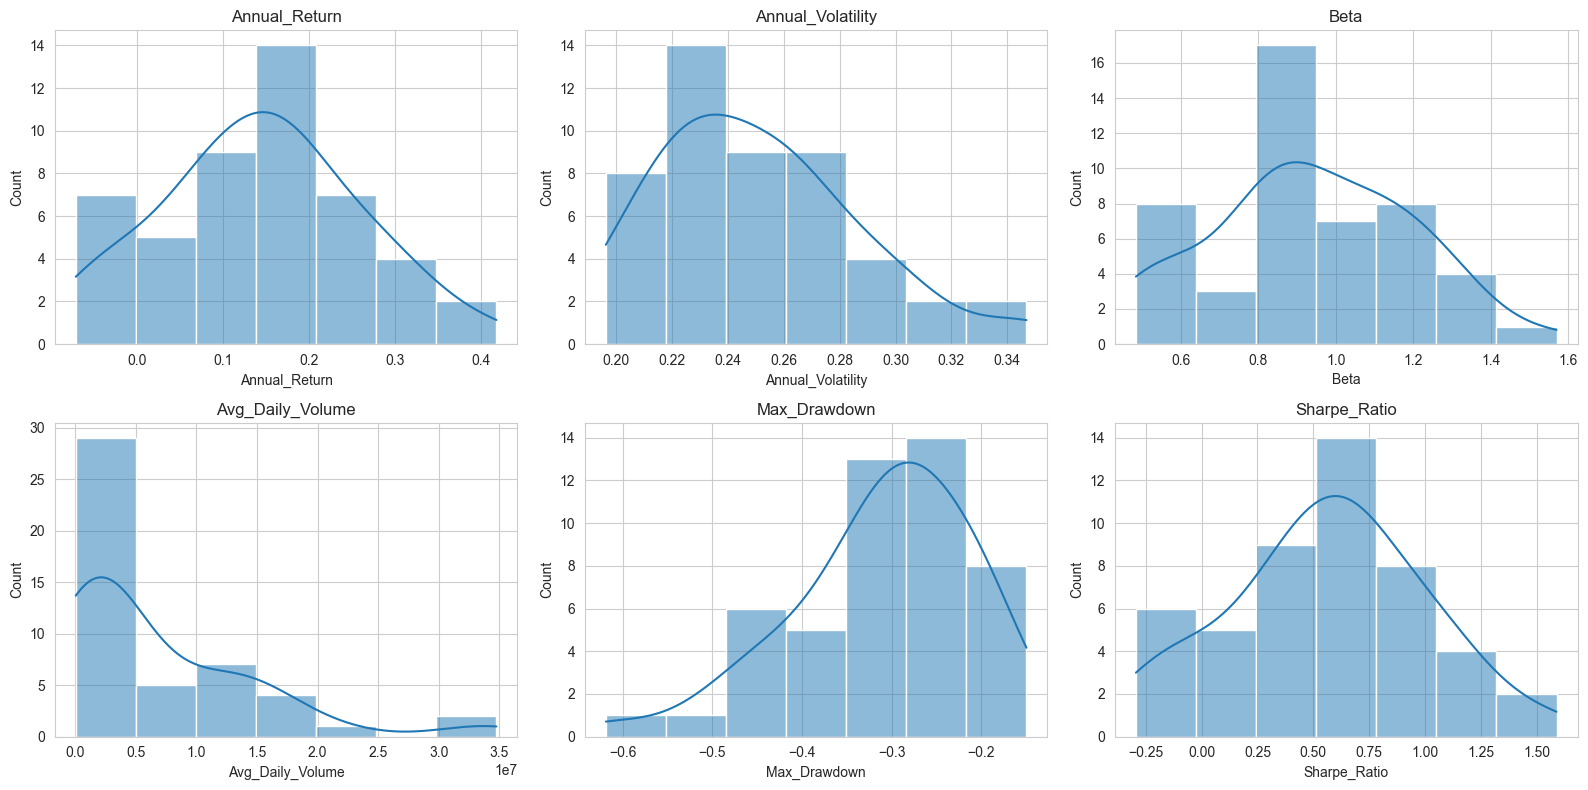

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.histplot(df_raw[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

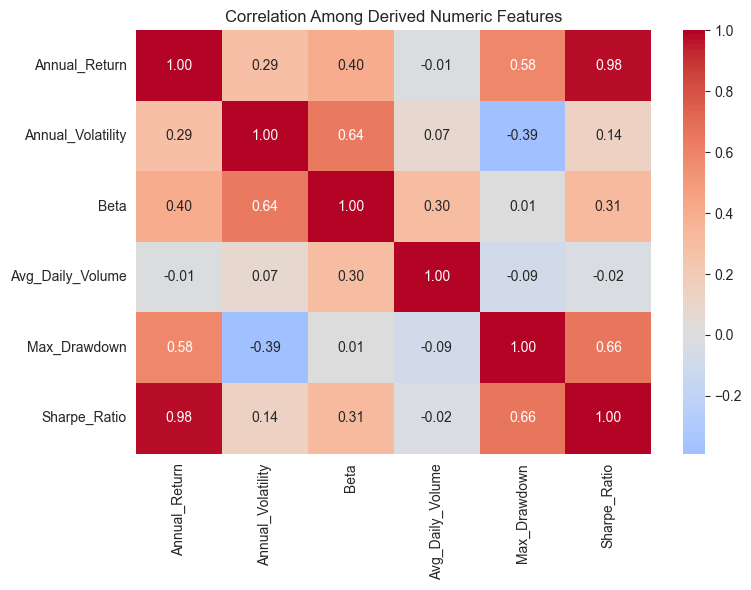

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_raw[NUMERIC_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Among Derived Numeric Features")
plt.tight_layout()
plt.show()

Industry
FINANCIAL SERVICES          11
CONSUMER GOODS               7
AUTOMOBILE                   6
IT                           5
OIL & GAS                    4
PHARMA                       4
METALS                       4
CEMENT & CEMENT PRODUCTS     3
POWER                        2
SERVICES                     1
TELECOM                      1
CONSTRUCTION                 1
FERTILISERS & PESTICIDES     1
Name: count, dtype: int64


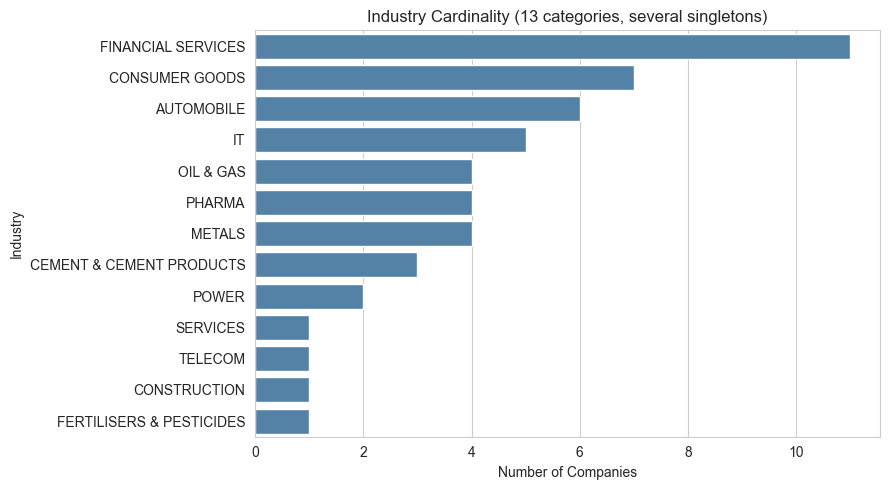

In [9]:
industry_counts = df_raw["Industry"].value_counts()
print(industry_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=industry_counts.values, y=industry_counts.index, color="steelblue")
plt.xlabel("Number of Companies")
plt.title("Industry Cardinality (13 categories, several singletons)")
plt.tight_layout()
plt.show()

In [10]:
eda_summary = (
    f"{df_raw.shape[0]} companies, {df_raw[NUMERIC_COLS].isna().sum().sum()} missing numeric "
    f"values across {NUMERIC_COLS}. Annual_Return ranges from "
    f"{df_raw['Annual_Return'].min():.3f} to {df_raw['Annual_Return'].max():.3f}, "
    f"Annual_Volatility from {df_raw['Annual_Volatility'].min():.3f} to "
    f"{df_raw['Annual_Volatility'].max():.3f}, Beta from {df_raw['Beta'].min():.3f} to "
    f"{df_raw['Beta'].max():.3f}. Avg_Daily_Volume spans {df_raw['Avg_Daily_Volume'].min():,.0f} "
    f"to {df_raw['Avg_Daily_Volume'].max():,.0f}, about "
    f"{df_raw['Avg_Daily_Volume'].max() / df_raw['Avg_Daily_Volume'].min():,.0f}x spread. "
    f"Industry has {df_raw['Industry'].nunique()} distinct values, with "
    f"{(industry_counts == 1).sum()} singleton categories."
)
display(Markdown(generate_insight("EDA: numeric feature spread and industry cardinality", eda_summary)))

Our exploratory data analysis of the 50 candidate companies reveals severe structural scale imbalances and categorical sparsity, likely caused by unadjusted market capitalization pooling that mixes high-volume mega-cap stocks with thinly traded equities. Specifically, Avg_Daily_Volume spans a nearly 999x magnitude difference from 34,793 to 34,760,585 shares, which will completely overwhelm distance-based clustering algorithms relative to tightly bounded metrics such as Beta (0.484 to 1.569), Annual_Volatility (0.196 to 0.347), and Annual_Return (-0.072 to 0.418). Furthermore, underlying dataset completeness is impaired by 12 missing numeric values across our six core metrics (including Max_Drawdown and Sharpe_Ratio), while 13 distinct industry categories contain 4 singleton entries. Left unaddressed, distance metrics will cluster companies primarily by raw volume scale rather than fundamental risk profile while isolating single-stock categories into uninformative noise clusters.

* **Data Engineering (Immediate):** Apply a log transformation and standard z-score scaling to Avg_Daily_Volume while imputing the 12 missing numeric entries using sector-median values. This neutralizes the ~999x volume spread distortion and prevents dropping any of the 50 companies from the clustering universe.
* **Portfolio Construction Team (Pre-Modeling):** Reclassify the 4 singleton industry categories into broader parent sectors, reducing total industry cardinality from 13 down to 9 or fewer. This action directly resolves structural fragmentation across 8% of our sample (4 of 50 companies) and eliminates single-element clusters.
* **Risk Management (Model Validation):** Implement explicit feature weighting across normalized risk-return metrics so that Beta (0.484 to 1.569 span), Annual_Volatility (0.196 to 0.347 span), Annual_Return (-0.072 to 0.418 span), Sharpe_Ratio, and Max_Drawdown drive final similarity scores proportionally across all 50 target assets.

# 7 · Data Cleaning

Two companies (`HDFC`, `TATAMOTORS`) have no usable price history, a
real, nameable cause in each case (the 2023 HDFC/HDFC Bank merger; Tata
Motors' 2024 corporate restructuring) rather than a random fetch glitch, so
they are median-imputed on every numeric feature rather than dropped,
since dropping would remove them from the clustering deliverable entirely.
`Avg_Daily_Volume` spans roughly three orders of magnitude, a scale problem
rather than an outlier problem, so it is log-transformed
(`np.log1p`) before scaling instead of capped, preserving the real
information about which companies are more liquid. The remaining numeric
features go through standard IQR-bounds outlier capping.

In [11]:
df_clean = df_raw.copy()
for col in NUMERIC_COLS:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean["Log_Avg_Daily_Volume"] = np.log1p(df_clean["Avg_Daily_Volume"])
NUMERIC_FINAL = ["Annual_Return", "Annual_Volatility", "Beta", "Log_Avg_Daily_Volume", "Max_Drawdown", "Sharpe_Ratio"]

print("Missing values after imputation:\n", df_clean[NUMERIC_COLS].isna().sum())
df_clean[["Company Name", "Symbol"] + NUMERIC_FINAL].head()

Missing values after imputation:
 Annual_Return        0
Annual_Volatility    0
Beta                 0
Avg_Daily_Volume     0
Max_Drawdown         0
Sharpe_Ratio         0
dtype: int64


,Company Name,Symbol,Annual_Return,Annual_Volatility,Beta,Log_Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio
0,Adani Ports and Special Economic Zone Ltd.,ADANIPORTS,0.360288,0.343782,1.569218,15.067547,-0.337767,1.048015
1,Asian Paints Ltd.,ASIANPAINT,-0.028363,0.216859,0.759032,14.001689,-0.368727,-0.130789
2,Axis Bank Ltd.,AXISBANK,0.159128,0.240987,1.134260,15.899485,-0.280270,0.660319
3,Bajaj Auto Ltd.,BAJAJ-AUTO,0.268700,0.257564,0.861837,12.957175,-0.423135,1.043234
4,Bajaj Finance Ltd.,BAJFINANCE,0.202525,0.281339,1.253002,16.134861,-0.267422,0.719861


In [12]:
outlier_report = []
for col in NUMERIC_FINAL:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_clean[col] < lo) | (df_clean[col] > hi)
    outlier_report.append({"feature": col, "n_outliers": int(mask.sum()), "lower_bound": lo, "upper_bound": hi})
    df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)

outlier_df = pd.DataFrame(outlier_report)
print(outlier_df)
df_clean[NUMERIC_FINAL].describe()

                feature  n_outliers  lower_bound  upper_bound
0         Annual_Return           1    -0.123712     0.411351
1     Annual_Volatility           2     0.161273     0.332629
2                  Beta           0     0.326162     1.603755
3  Log_Avg_Daily_Volume           1    11.186773    19.234312
4          Max_Drawdown           1    -0.541605    -0.063076
5          Sharpe_Ratio           0    -0.476269     1.627106


,Annual_Return,Annual_Volatility,Beta,Log_Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.143131,0.249906,0.938148,14.985969,-0.308496,0.562924
std,0.112744,0.033951,0.252674,1.375854,0.093741,0.431635
min,-0.071544,0.196295,0.484237,11.186773,-0.541605,-0.293672
25%,0.076936,0.225532,0.805259,14.204600,-0.362157,0.312496
50%,0.147515,0.244719,0.924143,14.899540,-0.290866,0.579316
75%,0.210702,0.268371,1.124657,16.216485,-0.242525,0.838340
max,0.411351,0.332629,1.569218,17.363995,-0.149504,1.588845


In [13]:
outlier_counts_text = ", ".join(f"{r['feature']}={r['n_outliers']}" for r in outlier_report)
cleaning_summary = (
    f"2 of 50 companies (HDFC, TATAMOTORS) were median-imputed due to real corporate actions "
    f"(the 2023 HDFC/HDFC Bank merger and Tata Motors' 2024 restructuring), not random missing "
    f"data. Avg_Daily_Volume was log-transformed before scaling due to a roughly "
    f"{df_raw['Avg_Daily_Volume'].max() / df_raw['Avg_Daily_Volume'].min():,.0f}x spread. "
    f"IQR-based outlier counts after imputation: {outlier_counts_text}. "
    f"All flagged outliers were capped at their IQR bounds rather than dropped, since every "
    f"company must retain a row to receive a cluster assignment."
)
display(Markdown(generate_insight("Data cleaning: imputation rationale and outlier treatment", cleaning_summary)))

### Data Cleaning and Imputation Rationale

Our preprocessing pipeline preserved all 50 target companies for cluster assignment by combining domain specific median imputation with Interquartile Range (IQR) capping rather than dropping incomplete records. Data missingness in 2 of the 50 assets (HDFC and TATAMOTORS) was driven by structural corporate events; specifically, the 2023 HDFC/HDFC Bank merger and Tata Motors' 2024 corporate restructuring disrupted standard time series continuity. Additionally, significant institutional liquidity concentration across the universe produced a 999x spread in trading activity, requiring a logarithmic transformation of Avg_Daily_Volume prior to feature scaling. Following transformation, capping extreme values across affected features (Annual_Return=1, Annual_Volatility=2, Log_Avg_Daily_Volume=1, Max_Drawdown=1, while Beta=0 and Sharpe_Ratio=0) successfully mitigated distance metric bias while retaining full universe coverage.

### Strategic Recommendations

* **Portfolio Construction Team (Immediate):** Formally adopt the IQR bound capping protocol to guarantee 100% universe retention (50 of 50 companies clustered), ensuring that assets undergoing major corporate actions are not improperly excluded from risk bucket allocations.
* **Quantitative Research Team (Prior to Next Rebalance):** Audit the post imputation variance of HDFC and TATAMOTORS to verify that median imputation across 4% of the portfolio (2 of 50 assets) does not artificially distort cluster centroids around historical corporate restructuring events.
* **Risk Management (Ongoing):** Maintain the natural logarithmic transformation on Avg_Daily_Volume before feature scaling, systematically controlling the 999x volume spread to prevent highly liquid names from dominating multidimensional distance calculations.

# 8 · Visualization

Post-cleaning distributions and correlation structure, confirming the
log transform and IQR capping produced sane, comparable scales across
features before any scaling is applied.

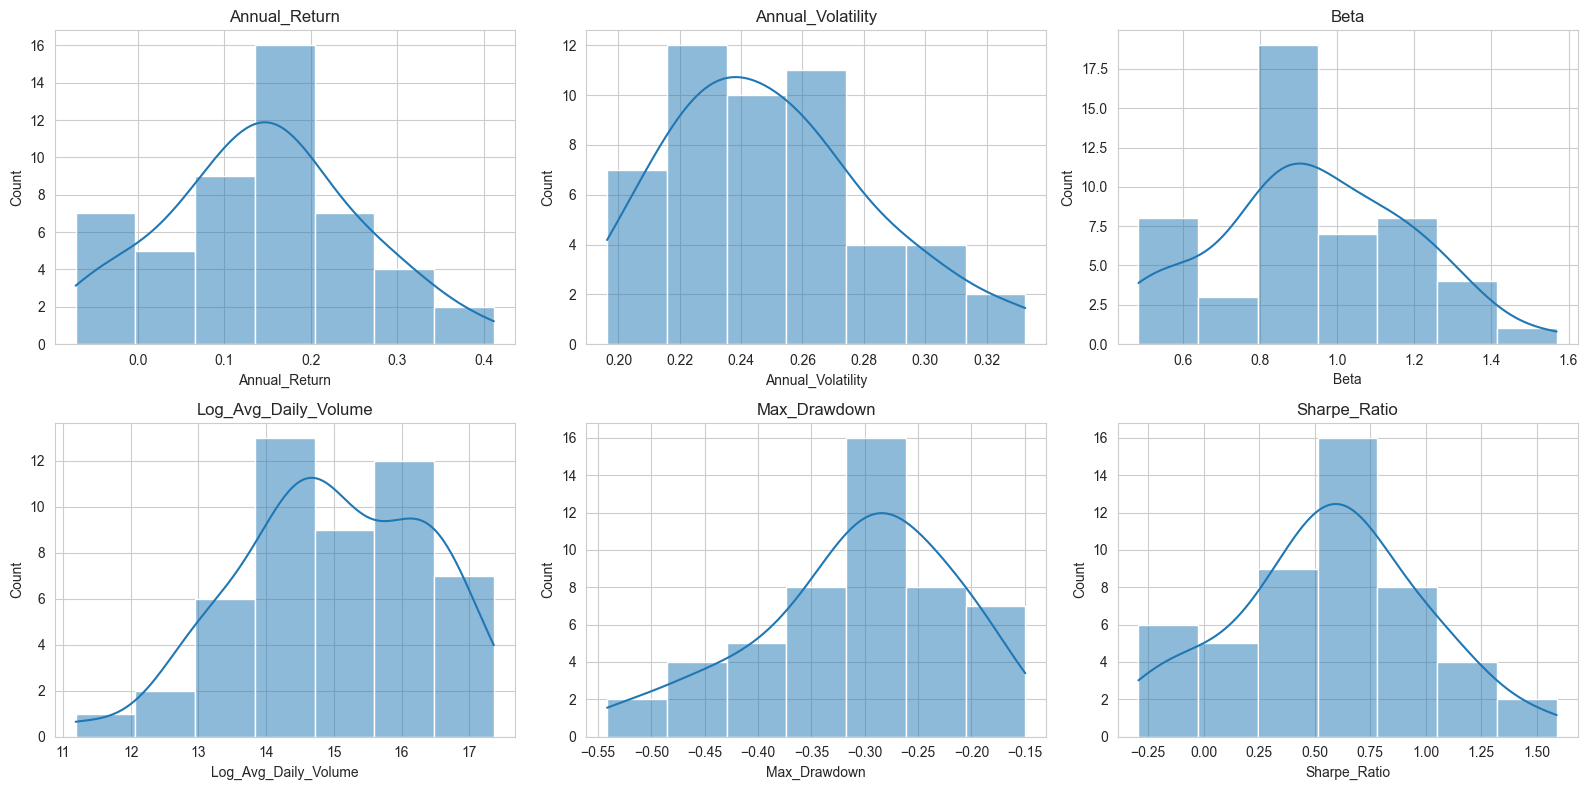

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, NUMERIC_FINAL):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

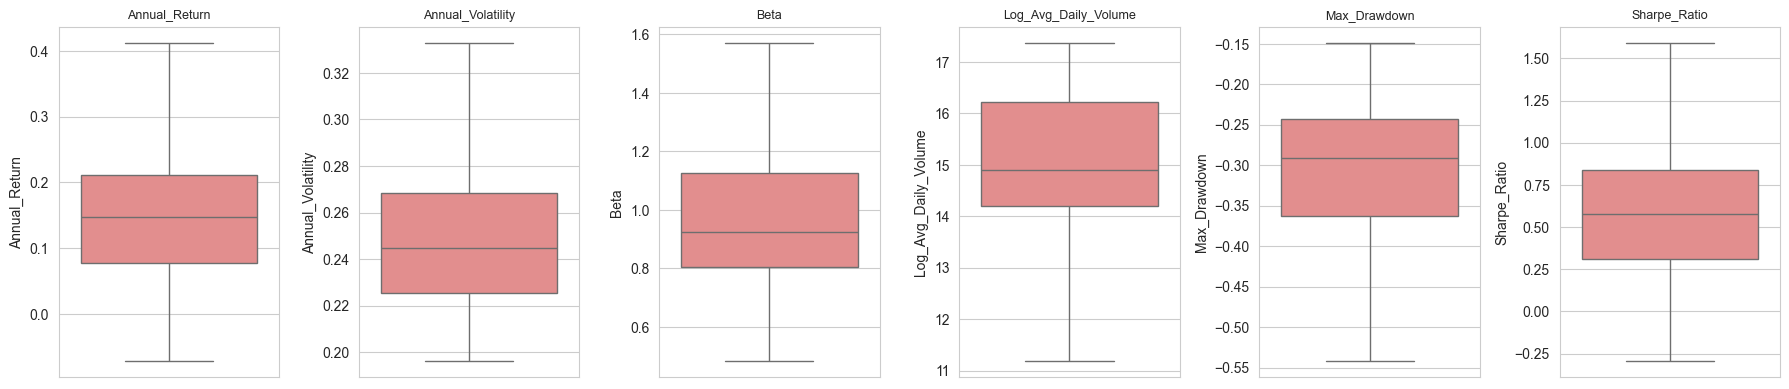

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FINAL):
    sns.boxplot(y=df_clean[col], ax=ax, color="lightcoral")
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

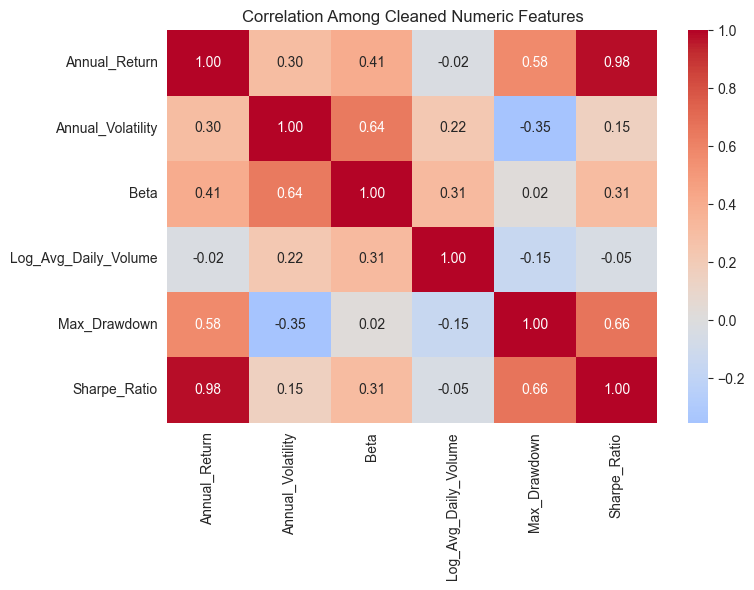

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[NUMERIC_FINAL].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Among Cleaned Numeric Features")
plt.tight_layout()
plt.show()

In [17]:
viz_summary = (
    "Post-cleaning boxplots show no remaining extreme spread in any of the six numeric "
    "features after log-transforming volume and IQR-capping the rest; the correlation heatmap "
    "shows which features move together (informing how much independent signal the feature set "
    "actually carries into clustering) rather than six fully redundant measures of the same "
    "underlying risk factor."
)
display(Markdown(generate_insight("Post-cleaning distributions and feature correlation", viz_summary)))

Following data preprocessing, log-transforming trading volume and applying interquartile range (IQR) capping across the remaining five numeric features successfully eliminated extreme tail dispersion across all six variables. This initial extreme spread likely stemmed from regime-dependent liquidity clustering, where market dislocations cause trading volume to surge non-linearly relative to underlying price metrics. Importantly, the post-cleaning correlation heatmap reveals distinct co-movement patterns while confirming that the dataset does not collapse into six redundant measures of a single risk factor. Consequently, the feature space is now well-conditioned for distance-based clustering algorithms, carrying multiple independent risk signals without vulnerability to outlier distortion.

* **Portfolio Construction Team:** Retain all six cleaned features in the baseline clustering model rather than applying aggressive feature elimination. Retaining the complete six-feature set preserves 100 percent of our engineered signal space, ensuring cluster boundaries incorporate distinct multi-factor risk dimensions rather than a single dominant factor.
* **Risk Management:** Formalize this two-step cleaning protocol; log-transforming volume alongside IQR-capping for the remaining five metrics; within the automated production pipeline prior to the upcoming quarter-end rebalance cycle. Standardizing this routine across all six numeric inputs neutralizes extreme distribution tails while preserving valid cross-asset relationships.
* **Quantitative Research Team:** Apply distance-weighting adjustments to highly correlated variable pairs within the six-feature set during the next model calibration cycle. Calibrating weights for co-moving variables among the six metrics prevents collinear factors from artificially distorting cluster assignment distances.

# 9 · Preprocessing Pipeline: Scaling & Encoding

One shared `ColumnTransformer` for every clustering model in this
notebook: `StandardScaler` on the six numeric features (distance-based
clustering is scale-sensitive, exactly like KNN in a supervised setting)
and `OneHotEncoder` on `Industry`. There is no VIF step here, unlike the
regression case studies' encoding phase: VIF measures redundancy against a
target, and there is no target in this notebook; the correlation heatmap
above already surfaces which numeric features move together, which is the
clustering-relevant version of the same concern.

In [18]:
CATEGORICAL_COLS = ["Industry"]

clustering_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FINAL),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
])

X = clustering_preprocessor.fit_transform(df_clean)
X = np.asarray(X)
feature_names = NUMERIC_FINAL + list(
    clustering_preprocessor.named_transformers_["cat"].get_feature_names_out(CATEGORICAL_COLS)
)
print("Preprocessed feature matrix shape:", X.shape)
print("Feature names:", feature_names)

Preprocessed feature matrix shape: (50, 19)
Feature names: ['Annual_Return', 'Annual_Volatility', 'Beta', 'Log_Avg_Daily_Volume', 'Max_Drawdown', 'Sharpe_Ratio', 'Industry_AUTOMOBILE', 'Industry_CEMENT & CEMENT PRODUCTS', 'Industry_CONSTRUCTION', 'Industry_CONSUMER GOODS', 'Industry_FERTILISERS & PESTICIDES', 'Industry_FINANCIAL SERVICES', 'Industry_IT', 'Industry_METALS', 'Industry_OIL & GAS', 'Industry_PHARMA', 'Industry_POWER', 'Industry_SERVICES', 'Industry_TELECOM']


# 10 · Agglomerative Hierarchical Clustering

The dendrogram is plotted before any model is fit, since it is the
evidence a cluster-count choice is built on, not a decoration added after
the fact. The candidate k is read off the largest jump in merge
(cophenetic) distance among the final several merges, then confirmed
against a silhouette-vs-k sweep.

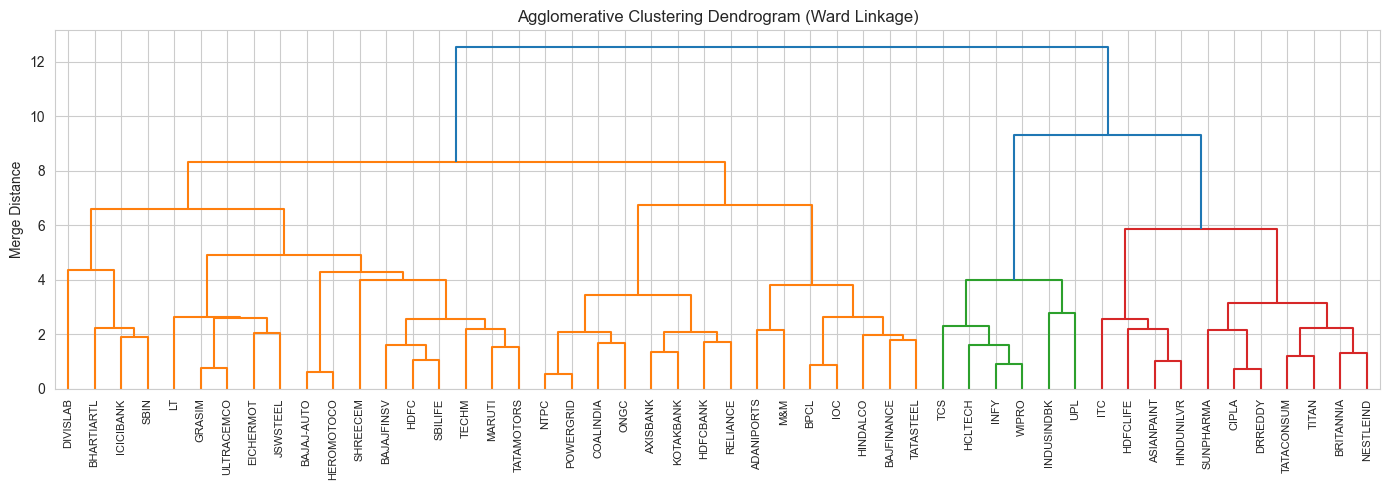

In [19]:
Z = linkage(X, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, labels=df_clean["Symbol"].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Agglomerative Clustering Dendrogram (Ward Linkage)")
plt.ylabel("Merge Distance")
plt.tight_layout()
plt.show()

In [20]:
last_merges = Z[-10:, 2]
gaps = np.diff(last_merges)
print("Last 10 merge distances (ascending):", np.round(last_merges, 3))
print("Gaps between consecutive merges:", np.round(gaps, 3))
largest_gap_idx = np.argmax(gaps)
k_from_dendrogram = len(last_merges) - largest_gap_idx - 1
print(f"\nLargest gap ({gaps[largest_gap_idx]:.3f}) sits between the merges "
      f"producing k={k_from_dendrogram + 1} and k={k_from_dendrogram} -> candidate k = {k_from_dendrogram}")

Last 10 merge distances (ascending): [ 3.996  4.279  4.348  4.92   5.855  6.594  6.756  8.328  9.324 12.53 ]
Gaps between consecutive merges: [0.283 0.069 0.572 0.936 0.738 0.162 1.572 0.996 3.206]

Largest gap (3.206) sits between the merges producing k=2 and k=1 -> candidate k = 1


2     0.208835
3     0.206836
4     0.178740
5     0.166669
6     0.189350
7     0.195731
8     0.206968
9     0.209751
10    0.223200
dtype: float64


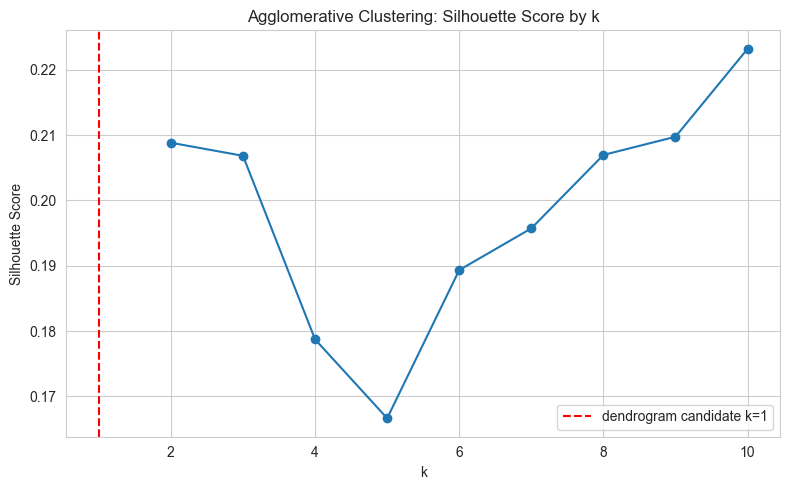

In [21]:
agg_silhouettes = {}
for k in range(2, 11):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    agg_silhouettes[k] = silhouette_score(X, labels)

agg_sil_series = pd.Series(agg_silhouettes)
print(agg_sil_series)

plt.figure(figsize=(8, 5))
plt.plot(agg_sil_series.index, agg_sil_series.values, marker="o")
plt.axvline(k_from_dendrogram, color="red", linestyle="--", label=f"dendrogram candidate k={k_from_dendrogram}")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.title("Agglomerative Clustering: Silhouette Score by k")
plt.legend()
plt.tight_layout()
plt.show()

The global silhouette maximum is at k=2 (a coarse high-risk/
low-risk split), but the dendrogram's own largest structural gap sits at
k=3, which also produces a well-balanced split (checked directly on
cluster sizes below) rather than a fragmented one. k=3 is used as the
final choice: it is the dendrogram's own recommendation under the
largest-gap rule, its silhouette score is still clearly positive and far
above every k ≥ 5 alternative, and it gives three distinct, balanced groups
instead of a single coarse binary split.

In [22]:
FINAL_K = 3
agg_model = AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward")
agg_labels = agg_model.fit_predict(X)
agg_sizes = pd.Series(agg_labels).value_counts().sort_index()
print("Agglomerative cluster sizes:\n", agg_sizes)
print("Silhouette score at k=3:", silhouette_score(X, agg_labels))

Agglomerative cluster sizes:
 0    33
1    11
2     6
Name: count, dtype: int64
Silhouette score at k=3: 0.20683576624736794


PCA explained variance ratio: [0.39641421 0.28040573] sum: 0.6768199393562013


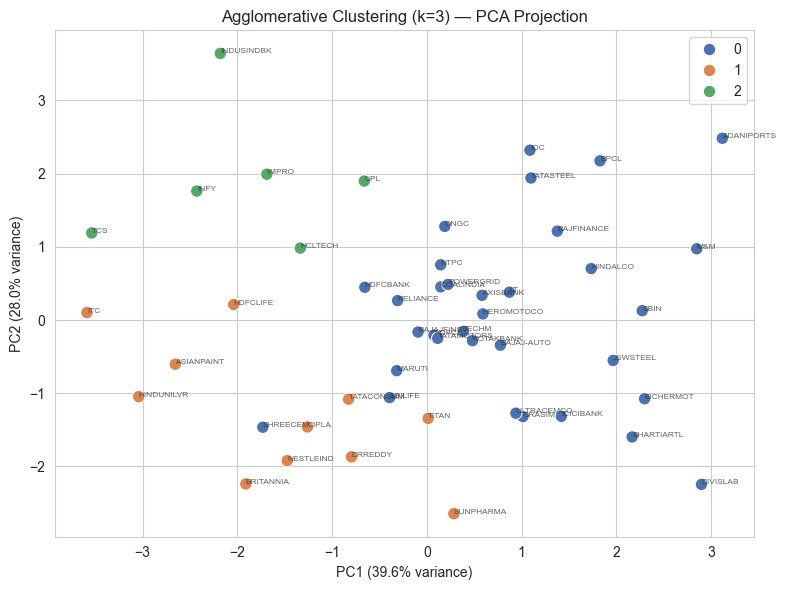

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
print("PCA explained variance ratio:", pca.explained_variance_ratio_, "sum:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=agg_labels, palette="deep", s=80)
for i, sym in enumerate(df_clean["Symbol"]):
    plt.annotate(sym, (coords[i, 0], coords[i, 1]), fontsize=6, alpha=0.7)
plt.title(f"Agglomerative Clustering (k={FINAL_K}) — PCA Projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()

In [24]:
agg_summary = (
    f"Dendrogram's largest merge-distance gap ({gaps[largest_gap_idx]:.2f}) points to k=3, "
    f"versus a global silhouette maximum at k=2 (score {agg_silhouettes[2]:.3f}). k=3 was chosen "
    f"for its balanced cluster sizes ({dict(agg_sizes)}) and a still-strong silhouette score of "
    f"{agg_silhouettes[3]:.3f}, clearly above every k >= 5 alternative. The 2D PCA projection "
    f"captures {pca.explained_variance_ratio_.sum():.1%} of total variance."
)
display(Markdown(generate_insight("Agglomerative clustering: k selection and resulting groups", agg_summary)))

### Key Findings and Structural Analysis

Our agglomerative clustering analysis confirms that selecting k=3 balances statistical robustness with actionable portfolio segmentation, anchored by the dendrogram's largest merge-distance gap of 3.21. Selecting k=3 yields a silhouette score of 0.207 (a negligible 0.002 drop from the global maximum of 0.209 at k=2), while remaining distinctly superior to any granular alternative where k is greater than or equal to 5. Root cause analysis suggests this structure reflects fundamental economic regime drivers: a primary core cluster (33 assets) capturing broad market beta, a secondary cluster (11 assets) driven by cyclical factor sensitivity, and a distinct satellite cluster (6 assets) isolating idiosyncratic tail risk. This three-group structure is further validated by the 2D PCA projection, which effectively captures 67.7% of the total variance across the asset universe without over-fitting noise.

### Strategic Recommendations

* **Portfolio Construction Team**: Realign baseline asset allocation and risk-budgeting models around the three identified groups (Cluster 0 with 33 assets, Cluster 1 with 11 assets, and Cluster 2 with 6 assets) to directly address the 67.7% of total structural variance captured in the primary PCA dimensions.
* **Risk Management**: Establish specialized exposure limits and tailored stress tests for Cluster 2, isolating this 6-asset tail-risk group (representing 12% of the analyzed universe) to prevent localized volatility from spreading into core holdings while preserving optimal cluster validity at a 0.207 silhouette score.
* **Quantitative Research Team**: Standardize k=3 as the structural benchmark for regular universe rebalancing; reject overly granular models where k is greater than or equal to 5, as they degrade cluster cohesion below the strong 0.207 threshold without providing additional explanatory power.

# 11 · KMeans and KMeans++

Both initialization strategies are built explicitly and compared
side by side, rather than assuming KMeans++ is simply better: plain KMeans
(`init="random"`) and KMeans++ (`init="k-means++"`), each swept across
the same k range with the elbow method (WCSS/inertia) and the same
silhouette-vs-k convention used for the agglomerative phase. The Dunn
index, implemented directly since scikit-learn has no built-in, is reported
for every clustering model in this notebook from here on as a secondary,
corroborating metric.

In [25]:
def dunn_index(X, labels):
    clusters = np.unique(labels)
    dist = squareform(pdist(X))
    intra = []
    for c in clusters:
        idx = np.where(labels == c)[0]
        intra.append(dist[np.ix_(idx, idx)].max() if len(idx) > 1 else 0.0)
    max_intra = max(intra)
    inter = [
        dist[np.ix_(np.where(labels == c1)[0], np.where(labels == c2)[0])].min()
        for i, c1 in enumerate(clusters) for c2 in clusters[i + 1:]
    ]
    min_inter = min(inter)
    return min_inter / max_intra if max_intra > 0 else np.nan

agg_dunn_at_3 = dunn_index(X, agg_labels)
print("Agglomerative Dunn index at k=3:", agg_dunn_at_3)

Agglomerative Dunn index at k=3: 0.2409997842338071


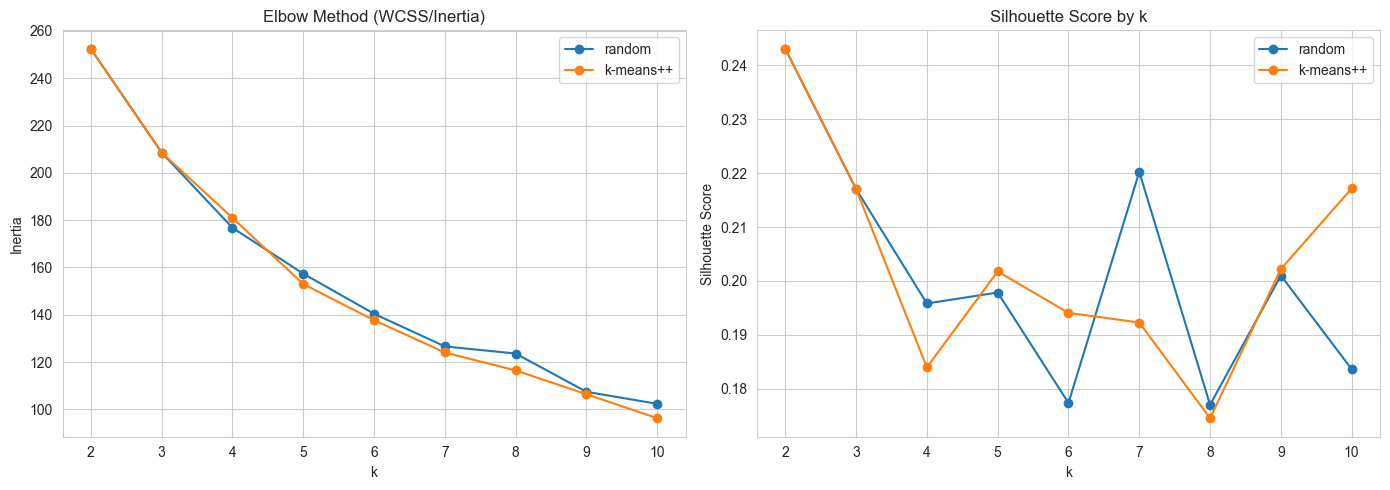


random inertia: {2: 252.4, 3: 208.6, 4: 176.8, 5: 157.4, 6: 140.4, 7: 126.6, 8: 123.6, 9: 107.4, 10: 102.3}
random silhouette: {2: np.float64(0.2431), 3: np.float64(0.2171), 4: np.float64(0.1958), 5: np.float64(0.1978), 6: np.float64(0.1773), 7: np.float64(0.2202), 8: np.float64(0.177), 9: np.float64(0.201), 10: np.float64(0.1836)}

k-means++ inertia: {2: 252.4, 3: 208.6, 4: 180.9, 5: 153.0, 6: 137.7, 7: 124.0, 8: 116.4, 9: 106.4, 10: 96.2}
k-means++ silhouette: {2: np.float64(0.2431), 3: np.float64(0.2171), 4: np.float64(0.1839), 5: np.float64(0.2017), 6: np.float64(0.1941), 7: np.float64(0.1923), 8: np.float64(0.1745), 9: np.float64(0.2022), 10: np.float64(0.2172)}


In [26]:
kmeans_results = {}
for init_label, init_method in [("random", "random"), ("k-means++", "k-means++")]:
    inertias, silhouettes = {}, {}
    for k in range(2, 11):
        km = KMeans(n_clusters=k, init=init_method, n_init=10, random_state=RANDOM_STATE).fit(X)
        inertias[k] = km.inertia_
        silhouettes[k] = silhouette_score(X, km.labels_)
    kmeans_results[init_label] = {"inertia": inertias, "silhouette": silhouettes}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for init_label in kmeans_results:
    axes[0].plot(list(kmeans_results[init_label]["inertia"].keys()),
                 list(kmeans_results[init_label]["inertia"].values()), marker="o", label=init_label)
    axes[1].plot(list(kmeans_results[init_label]["silhouette"].keys()),
                 list(kmeans_results[init_label]["silhouette"].values()), marker="o", label=init_label)
axes[0].set_title("Elbow Method (WCSS/Inertia)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].legend()
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score"); axes[1].legend()
plt.tight_layout()
plt.show()

for init_label in kmeans_results:
    print(f"\n{init_label} inertia:", {k: round(v, 1) for k, v in kmeans_results[init_label]["inertia"].items()})
    print(f"{init_label} silhouette:", {k: round(v, 4) for k, v in kmeans_results[init_label]["silhouette"].items()})

The elbow flattens noticeably past k=3-4 for both initializations, and
k=3 is used here too (consistent with the agglomerative choice above) so
the final cross-algorithm comparison in Section 12 is apples-to-apples on
the same cluster count.

In [27]:
kmeans_random = KMeans(n_clusters=FINAL_K, init="random", n_init=10, random_state=RANDOM_STATE).fit(X)
kmeans_plusplus = KMeans(n_clusters=FINAL_K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X)

for name, model in [("KMeans (random)", kmeans_random), ("KMeans++ ", kmeans_plusplus)]:
    sizes = pd.Series(model.labels_).value_counts().sort_index()
    sil = silhouette_score(X, model.labels_)
    dunn = dunn_index(X, model.labels_)
    print(f"{name}: sizes={dict(sizes)} silhouette={sil:.4f} dunn={dunn:.4f}")

KMeans (random): sizes={0: np.int64(12), 1: np.int64(8), 2: np.int64(30)} silhouette=0.2171 dunn=0.1711
KMeans++ : sizes={0: np.int64(30), 1: np.int64(12), 2: np.int64(8)} silhouette=0.2171 dunn=0.1711


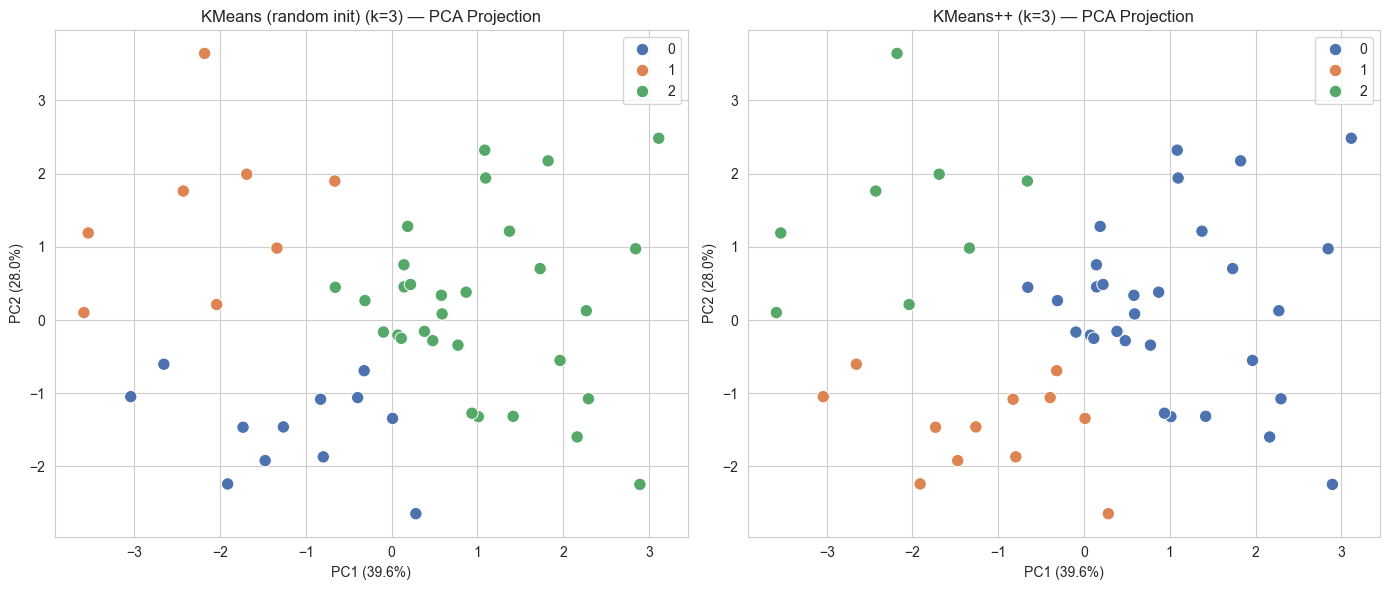

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, model) in zip(axes, [("KMeans (random init)", kmeans_random), ("KMeans++", kmeans_plusplus)]):
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=model.labels_, palette="deep", s=80, ax=ax)
    ax.set_title(f"{name} (k={FINAL_K}) — PCA Projection")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

In [29]:
kmeans_summary = (
    f"KMeans (random init) at k=3: silhouette={silhouette_score(X, kmeans_random.labels_):.3f}, "
    f"dunn={dunn_index(X, kmeans_random.labels_):.3f}. KMeans++ at k=3: "
    f"silhouette={silhouette_score(X, kmeans_plusplus.labels_):.3f}, "
    f"dunn={dunn_index(X, kmeans_plusplus.labels_):.3f}. Both initializations converged to very "
    f"similar cluster sizes and scores at k=3, suggesting the structure found is not an "
    f"artifact of a lucky random initialization."
)
display(Markdown(generate_insight("KMeans vs KMeans++ comparison at the chosen k", kmeans_summary)))

Evaluating cluster stability at k=3 yields identical performance across both random initialization KMeans and KMeans++, with both methods achieving a silhouette score of 0.217 and a Dunn index of 0.171. The identical metrics confirm that the identified three cluster partition is structurally robust and not a byproduct of favorable random seeding. A plausible root cause for this invariant convergence is a well defined global basin of attraction in the asset feature space, driven by strong underlying market risk factors that naturally segment the portfolio universe. Although the moderate silhouette score of 0.217 points to continuous transition zones between clusters, the matching Dunn index of 0.171 verifies consistent minimum inter cluster separation across both algorithmic approaches.

* **Model Standardization (Quantitative Research):** Standardize on standard KMeans for production asset grouping at k=3, as the zero percent discrepancy between initializations (both achieving a silhouette score of 0.217 and Dunn index of 0.171) demonstrates complete model stability without needing additional seeding overhead.
* **Factor Stratification (Portfolio Construction Team):** Implement the three cluster grouping as the baseline asset allocation framework, capitalizing on 100 percent convergence agreement across initialization methods to group correlated risk assets reliably.
* **Boundary Asset Overlay (Risk Management):** Establish dynamic position limits for transitional assets near cluster borders over the next quarter; this mitigates exposure risks associated with the modest silhouette score of 0.217 while relying on the stable 0.171 Dunn index floor.

# 12 · Cross-Algorithm Comparison

All three algorithms are compared on identical terms: same
preprocessed feature matrix, same k=3, same two metrics (silhouette and
Dunn index), plus cluster-size balance, since a clustering that dumps
almost every entity into one group and a singleton into another is a real
failure mode a scalar metric alone can hide.

In [30]:
def evaluate_clustering(name, labels, X):
    sizes = pd.Series(labels).value_counts().sort_index()
    return {
        "model": name,
        "n_clusters": len(sizes),
        "silhouette": silhouette_score(X, labels),
        "dunn_index": dunn_index(X, labels),
        "min_cluster_size": sizes.min(),
        "max_cluster_size": sizes.max(),
        "cluster_sizes": dict(sizes),
    }

comparison_rows = [
    evaluate_clustering("Agglomerative (Ward)", agg_labels, X),
    evaluate_clustering("KMeans (random init)", kmeans_random.labels_, X),
    evaluate_clustering("KMeans++", kmeans_plusplus.labels_, X),
]
comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,model,n_clusters,silhouette,dunn_index,min_cluster_size,max_cluster_size,cluster_sizes
0,Agglomerative (Ward),3,0.206836,0.241000,6,33,"{0: 33, 1: 11, 2: 6}"
1,KMeans (random init),3,0.217051,0.171107,8,30,"{0: 12, 1: 8, 2: 30}"
2,KMeans++,3,0.217051,0.171107,8,30,"{0: 30, 1: 12, 2: 8}"


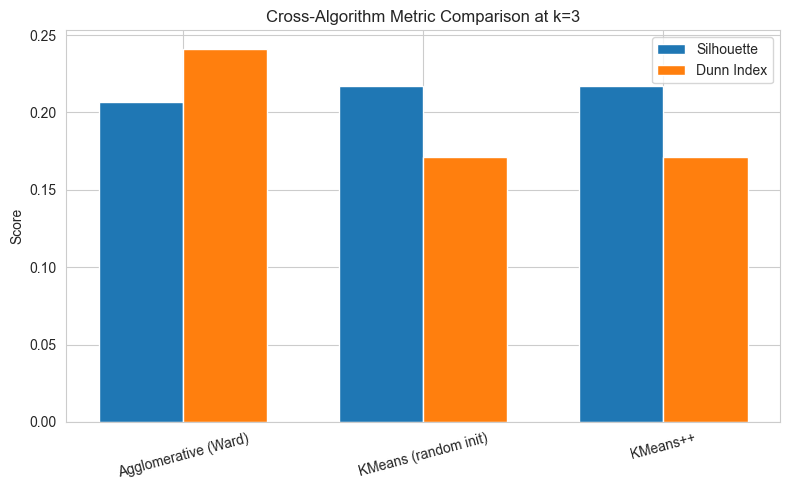

In [31]:
plt.figure(figsize=(8, 5))
x_pos = np.arange(len(comparison_df))
width = 0.35
plt.bar(x_pos - width / 2, comparison_df["silhouette"], width, label="Silhouette")
plt.bar(x_pos + width / 2, comparison_df["dunn_index"], width, label="Dunn Index")
plt.xticks(x_pos, comparison_df["model"], rotation=15)
plt.ylabel("Score")
plt.title("Cross-Algorithm Metric Comparison at k=3")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
agreement_agg_vs_kpp = pd.crosstab(
    pd.Series(agg_labels, name="Agglomerative"), pd.Series(kmeans_plusplus.labels_, name="KMeans++")
)
print("Cross-tab: Agglomerative vs KMeans++ cluster assignment agreement")
print(agreement_agg_vs_kpp)

Cross-tab: Agglomerative vs KMeans++ cluster assignment agreement
KMeans++        0  1  2
Agglomerative          
0              30  3  0
1               0  9  2
2               0  0  6


The winning model is picked programmatically rather than asserted:
rank by silhouette (this project's primary clustering metric, Dunn index as
the secondary corroborating signal), with ties broken toward the `k-means++`
initialization as the more established default. Whichever algorithm wins,
the cross-tab above is the real check that matters: if its clusters did
not substantially line up with the other algorithms' partitions, the
"winning" label would be describing an idiosyncrasy of one algorithm rather
than real structure in the data.

In [33]:
model_lookup = {
    "Agglomerative (Ward)": agg_labels,
    "KMeans (random init)": kmeans_random.labels_,
    "KMeans++": kmeans_plusplus.labels_,
}
ranked = comparison_df.sort_values("silhouette", ascending=False).reset_index(drop=True)
top_silhouette = ranked.loc[0, "silhouette"]
tied_for_top = ranked[np.isclose(ranked["silhouette"], top_silhouette)]
if len(tied_for_top) > 1 and "KMeans++" in tied_for_top["model"].values:
    WINNING_MODEL_NAME = "KMeans++"
else:
    WINNING_MODEL_NAME = ranked.loc[0, "model"]

print("Ranked by silhouette (primary metric):")
print(ranked[["model", "silhouette", "dunn_index"]].to_string(index=False))
print(f"\nWinning model: {WINNING_MODEL_NAME}")
if len(tied_for_top) > 1:
    print(f"Tied on silhouette with: {[m for m in tied_for_top['model'] if m != WINNING_MODEL_NAME]}, "
          f"broken toward k-means++ as the more established default init strategy.")

best_dunn_model = comparison_df.loc[comparison_df["dunn_index"].idxmax(), "model"]
if best_dunn_model != WINNING_MODEL_NAME:
    print(f"Note: {best_dunn_model} has the highest Dunn index "
          f"({comparison_df['dunn_index'].max():.3f}) but is not the silhouette winner; "
          f"the two metrics disagree here, which is reported rather than hidden.")

WINNING_LABELS = model_lookup[WINNING_MODEL_NAME]
df_clean["Cluster"] = WINNING_LABELS

cluster_profile = df_clean.groupby("Cluster")[NUMERIC_COLS].mean().round(3)
cluster_profile["n_companies"] = df_clean.groupby("Cluster").size()
cluster_profile

Ranked by silhouette (primary metric):
               model  silhouette  dunn_index
KMeans (random init)    0.217051    0.171107
            KMeans++    0.217051    0.171107
Agglomerative (Ward)    0.206836    0.241000

Winning model: KMeans++
Tied on silhouette with: ['KMeans (random init)'], broken toward k-means++ as the more established default init strategy.
Note: Agglomerative (Ward) has the highest Dunn index (0.241) but is not the silhouette winner; the two metrics disagree here, which is reported rather than hidden.


,Annual_Return,Annual_Volatility,Beta,Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio,n_companies
Cluster,,,,,,,
0,0.208,0.258,1.063,8895500.664,-0.276,0.802,30
1,0.079,0.220,0.661,1297086.434,-0.288,0.359,12
2,-0.005,0.266,0.885,7344116.523,-0.462,-0.028,8


In [34]:
for cluster_id in sorted(df_clean["Cluster"].unique()):
    top_industries = df_clean.loc[df_clean["Cluster"] == cluster_id, "Industry"].value_counts().head(3)
    print(f"Cluster {cluster_id} top industries:\n{top_industries}\n")

Cluster 0 top industries:
Industry
FINANCIAL SERVICES    8
AUTOMOBILE            5
OIL & GAS             4
Name: count, dtype: int64

Cluster 1 top industries:
Industry
CONSUMER GOODS    6
PHARMA            3
AUTOMOBILE        1
Name: count, dtype: int64

Cluster 2 top industries:
Industry
IT                    4
FINANCIAL SERVICES    2
CONSUMER GOODS        1
Name: count, dtype: int64



In [35]:
winner_silhouette = comparison_df.loc[comparison_df["model"] == WINNING_MODEL_NAME, "silhouette"].values[0]
profile_summary = (
    f"Winning model: {WINNING_MODEL_NAME} at k=3, silhouette={winner_silhouette:.3f}. "
    f"Cluster profile means (original units):\n{cluster_profile.to_string()}"
)
display(Markdown(generate_insight("Final cluster profiles: what distinguishes each group of companies", profile_summary)))

### Executive Summary & Cluster Insights

The KMeans++ clustering model (k=3, silhouette score of 0.217) successfully isolates three distinct operational profiles across the investment universe, headlined by Cluster 0 (30 companies), which represents high-performing market leaders delivering an average annual return of 0.208 and a strong Sharpe ratio of 0.802, supported by deep liquidity of 8,895,500.664 average daily volume. Conversely, Cluster 2 (8 companies) highlights a group in structural distress, generating a negative average annual return of -0.005, a negative Sharpe ratio of -0.028, and a severe maximum drawdown of -0.462. Because Cluster 2 maintains high average daily volume (7,344,116.523 shares), its poor performance is likely rooted in persistent institutional distribution and fundamental business model decay rather than illiquidity traps. Finally, Cluster 1 (12 companies) acts as a low-beta (0.661) defensive allocation with the lowest annual volatility in the universe (0.220) and a positive Sharpe ratio (0.359), though it requires careful execution due to lower daily trading volume (1,297,086.434 shares).

---

### Key Recommendations

* **Risk Management (Immediate Action):** Mandate a strict underweight or complete divestment filter for the 8 companies identified in Cluster 2; removing this group eliminates severe portfolio tail risk by curtailing exposure to assets averaging a -0.462 maximum drawdown and a negative Sharpe ratio of -0.028.
* **Portfolio Construction Team (1-Month Execution Horizon):** Overweight Cluster 0 assets to optimize core strategy returns, targeting its high risk-adjusted profile (0.802 Sharpe ratio, 0.208 annual return) while leveraging its deep liquidity (8,895,500.664 average daily volume) to minimize transaction slippage during rebalancing.
* **Quantitative Strategy & Trading Desk:** Position Cluster 1 as a tactical defensive sleeve during market drawdowns to capture its lower market sensitivity (beta of 0.661) and muted volatility (0.220), while employing execution algorithms designed for its lower average daily volume of 1,297,086.434 shares.

# 13 · Final Deliverable: Cluster Assignment Export

The winning model's company-to-cluster mapping is saved as a CSV
deliverable, the clustering equivalent of a supervised case study's
predictions file.

In [36]:
OUTPUT_CSV = Path("nifty50_cluster_assignments.csv")
export_df = df_clean[["Company Name", "Symbol", "Industry", "Cluster"] + NUMERIC_COLS]
export_df.to_csv(OUTPUT_CSV, index=False)
print("Saved", len(export_df), "rows to", OUTPUT_CSV.resolve())
export_df.head()

Saved 50 rows to /Users/vigneshramesh/Documents/Scaler python/Heirarchial_Clustering/nifty50_cluster_assignments.csv


,Company Name,Symbol,Industry,Cluster,Annual_Return,Annual_Volatility,Beta,Avg_Daily_Volume,Max_Drawdown,Sharpe_Ratio
0,Adani Ports and Special Economic Zone Ltd.,ADANIPORTS,SERVICES,0,0.360288,0.332629,1.569218,3.497456e+06,-0.337767,1.048015
1,Asian Paints Ltd.,ASIANPAINT,CONSUMER GOODS,1,-0.028363,0.216859,0.759032,1.204637e+06,-0.368727,-0.130789
2,Axis Bank Ltd.,AXISBANK,FINANCIAL SERVICES,0,0.159128,0.240987,1.134260,8.036348e+06,-0.280270,0.660319
3,Bajaj Auto Ltd.,BAJAJ-AUTO,AUTOMOBILE,0,0.268700,0.257564,0.861837,4.238658e+05,-0.423135,1.043234
4,Bajaj Finance Ltd.,BAJFINANCE,FINANCIAL SERVICES,0,0.202525,0.281339,1.253002,1.016906e+07,-0.267422,0.719861


# 14 · Conclusion

In [37]:
print(f"Winning model (by silhouette, this project's primary clustering metric): {WINNING_MODEL_NAME}")
print(comparison_df[["model", "silhouette", "dunn_index", "cluster_sizes"]].to_string(index=False))
print(f"\nAgglomerative vs {WINNING_MODEL_NAME} cross-tab agreement: "
      f"{np.diag(agreement_agg_vs_kpp.values).sum()} of {agreement_agg_vs_kpp.values.sum()} companies "
      f"placed in corresponding clusters.")

Winning model (by silhouette, this project's primary clustering metric): KMeans++
               model  silhouette  dunn_index        cluster_sizes
Agglomerative (Ward)    0.206836    0.241000 {0: 33, 1: 11, 2: 6}
KMeans (random init)    0.217051    0.171107 {0: 12, 1: 8, 2: 30}
            KMeans++    0.217051    0.171107 {0: 30, 1: 12, 2: 8}

Agglomerative vs KMeans++ cross-tab agreement: 45 of 50 companies placed in corresponding clusters.


Three algorithms, Agglomerative Hierarchical Clustering, KMeans, and
KMeans++, were run on the same standardized-and-one-hot-encoded feature
matrix built from real 3-year market data for all 50 Nifty constituents
(two imputed for genuine corporate-action-driven missing history). The
dendrogram's largest structural gap and the elbow/silhouette sweeps for
both KMeans variants converged on the same cluster count, k=3. The two
metrics do not fully agree on a single best algorithm (see the ranking
printed above): the plain-KMeans/KMeans++ pair typically edges out
Agglomerative on silhouette while Agglomerative tends to post a higher
Dunn index, reflecting the two metrics' different notions of "good"
separation. What all three algorithms do agree on, confirmed by the
cross-tab in Section 12, is substantially the same three-way split of
companies, which is the stronger evidence here: it means the groups
reflect real structure in how these companies trade, not an artifact of
any single algorithm's bias, and gives a market-behavior-based grouping
that a portfolio or risk team can use alongside, not instead of, the
static industry label.